In [ ]:
# Setup

import os
import random
import numpy as np
import pandas as pd
from tqdm import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import precision_score, recall_score, f1_score


# Symbolic ML imports
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
import xgboost as xgb
import lightgbm as lgb
import catboost as cb

# XAI imports
import shap
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

import warnings
warnings.filterwarnings("ignore")  

# Set seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)


Using device: cuda


C:\Users\MSC055\.conda\envs\pytorch2\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import timm
models = timm.list_models('*vit*')
print(models)

['convit_base', 'convit_small', 'convit_tiny', 'crossvit_9_240', 'crossvit_9_dagger_240', 'crossvit_15_240', 'crossvit_15_dagger_240', 'crossvit_15_dagger_408', 'crossvit_18_240', 'crossvit_18_dagger_240', 'crossvit_18_dagger_408', 'crossvit_base_240', 'crossvit_small_240', 'crossvit_tiny_240', 'davit_base', 'davit_base_fl', 'davit_giant', 'davit_huge', 'davit_huge_fl', 'davit_large', 'davit_small', 'davit_tiny', 'efficientvit_b0', 'efficientvit_b1', 'efficientvit_b2', 'efficientvit_b3', 'efficientvit_l1', 'efficientvit_l2', 'efficientvit_l3', 'efficientvit_m0', 'efficientvit_m1', 'efficientvit_m2', 'efficientvit_m3', 'efficientvit_m4', 'efficientvit_m5', 'fastvit_ma36', 'fastvit_mci0', 'fastvit_mci1', 'fastvit_mci2', 'fastvit_mci3', 'fastvit_mci4', 'fastvit_s12', 'fastvit_sa12', 'fastvit_sa24', 'fastvit_sa36', 'fastvit_t8', 'fastvit_t12', 'flexivit_base', 'flexivit_large', 'flexivit_small', 'gcvit_base', 'gcvit_small', 'gcvit_tiny', 'gcvit_xtiny', 'gcvit_xxtiny', 'levit_128', 'levit_1

Class: Central Serous Chorioretinopathy (Color Fundus), Number of Images: 101
Class: Diabetic Retinopathy, Number of Images: 1509
Class: Disc Edema, Number of Images: 127
Class: Glaucoma, Number of Images: 1349
Class: Healthy, Number of Images: 1024
Class: Macular Scar, Number of Images: 444
Class: Myopia, Number of Images: 500
Class: Pterygium, Number of Images: 17
Class: Retinal Detachment, Number of Images: 125
Class: Retinitis Pigmentosa, Number of Images: 139
{(2004, 1690)}
Corrupted Images: []


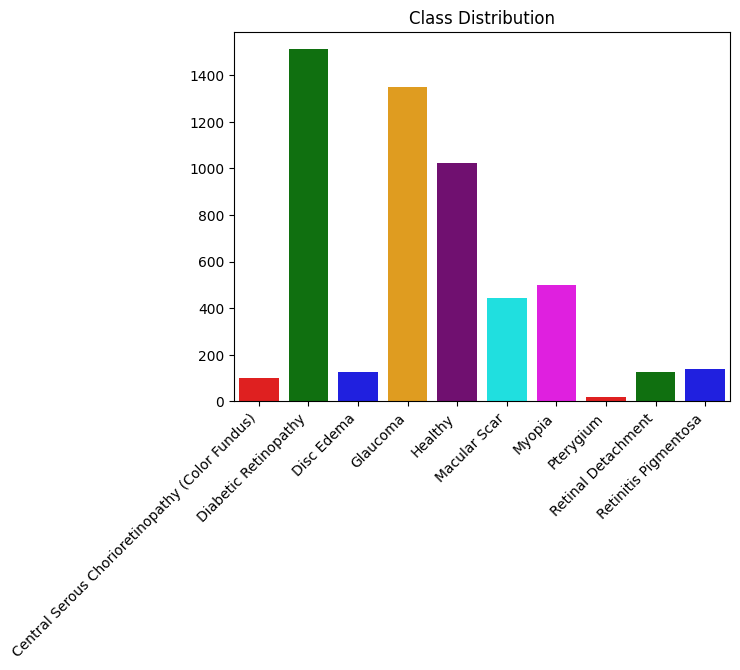

In [ ]:
# Dataset preparation

DATA_PATH = "C:/Users/MSC055/Desktop/Sabrina/Eye Image Dataset"
classes = os.listdir(DATA_PATH)
for cls in classes:
    print(f"Class: {cls}, Number of Images: {len(os.listdir(os.path.join(DATA_PATH, cls)))}")

CLASSES = [
    "Central Serous Chorioretinopathy (Color Fundus)",
    "Diabetic Retinopathy",
    "Disc Edema",
    "Glaucoma",
    "Healthy",
    "Macular Scar",
    "Myopia",
    "Pterygium",
    "Retinal Detachment",
    "Retinitis Pigmentosa"
]

from PIL import Image

image_sizes = []
for cls in classes:
    for img_file in os.listdir(os.path.join(DATA_PATH, cls)):
        img = Image.open(os.path.join(DATA_PATH, cls, img_file))
        image_sizes.append(img.size)

print(set(image_sizes))  # Unique image sizes

# To check any corrupted images
corrupted_images = []
for cls in classes:
    for img_file in os.listdir(os.path.join(DATA_PATH, cls)):
        try:
            img = Image.open(os.path.join(DATA_PATH, cls, img_file))
            img.verify()  # Check for corruption
        except (IOError, SyntaxError):
            corrupted_images.append(img_file)

print("Corrupted Images:", corrupted_images)

# To plot the class distribution
import matplotlib.pyplot as plt
import seaborn as sns

class_counts = [len(os.listdir(os.path.join(DATA_PATH, cls))) for cls in classes]
colors = ['red', 'green', 'blue', 'orange', 'purple', 'cyan', 'magenta']  # adjust to number of classes
sns.barplot(x=classes, y=class_counts, palette=colors)
plt.xticks(rotation=45, ha='right')
plt.title("Class Distribution")
plt.show()


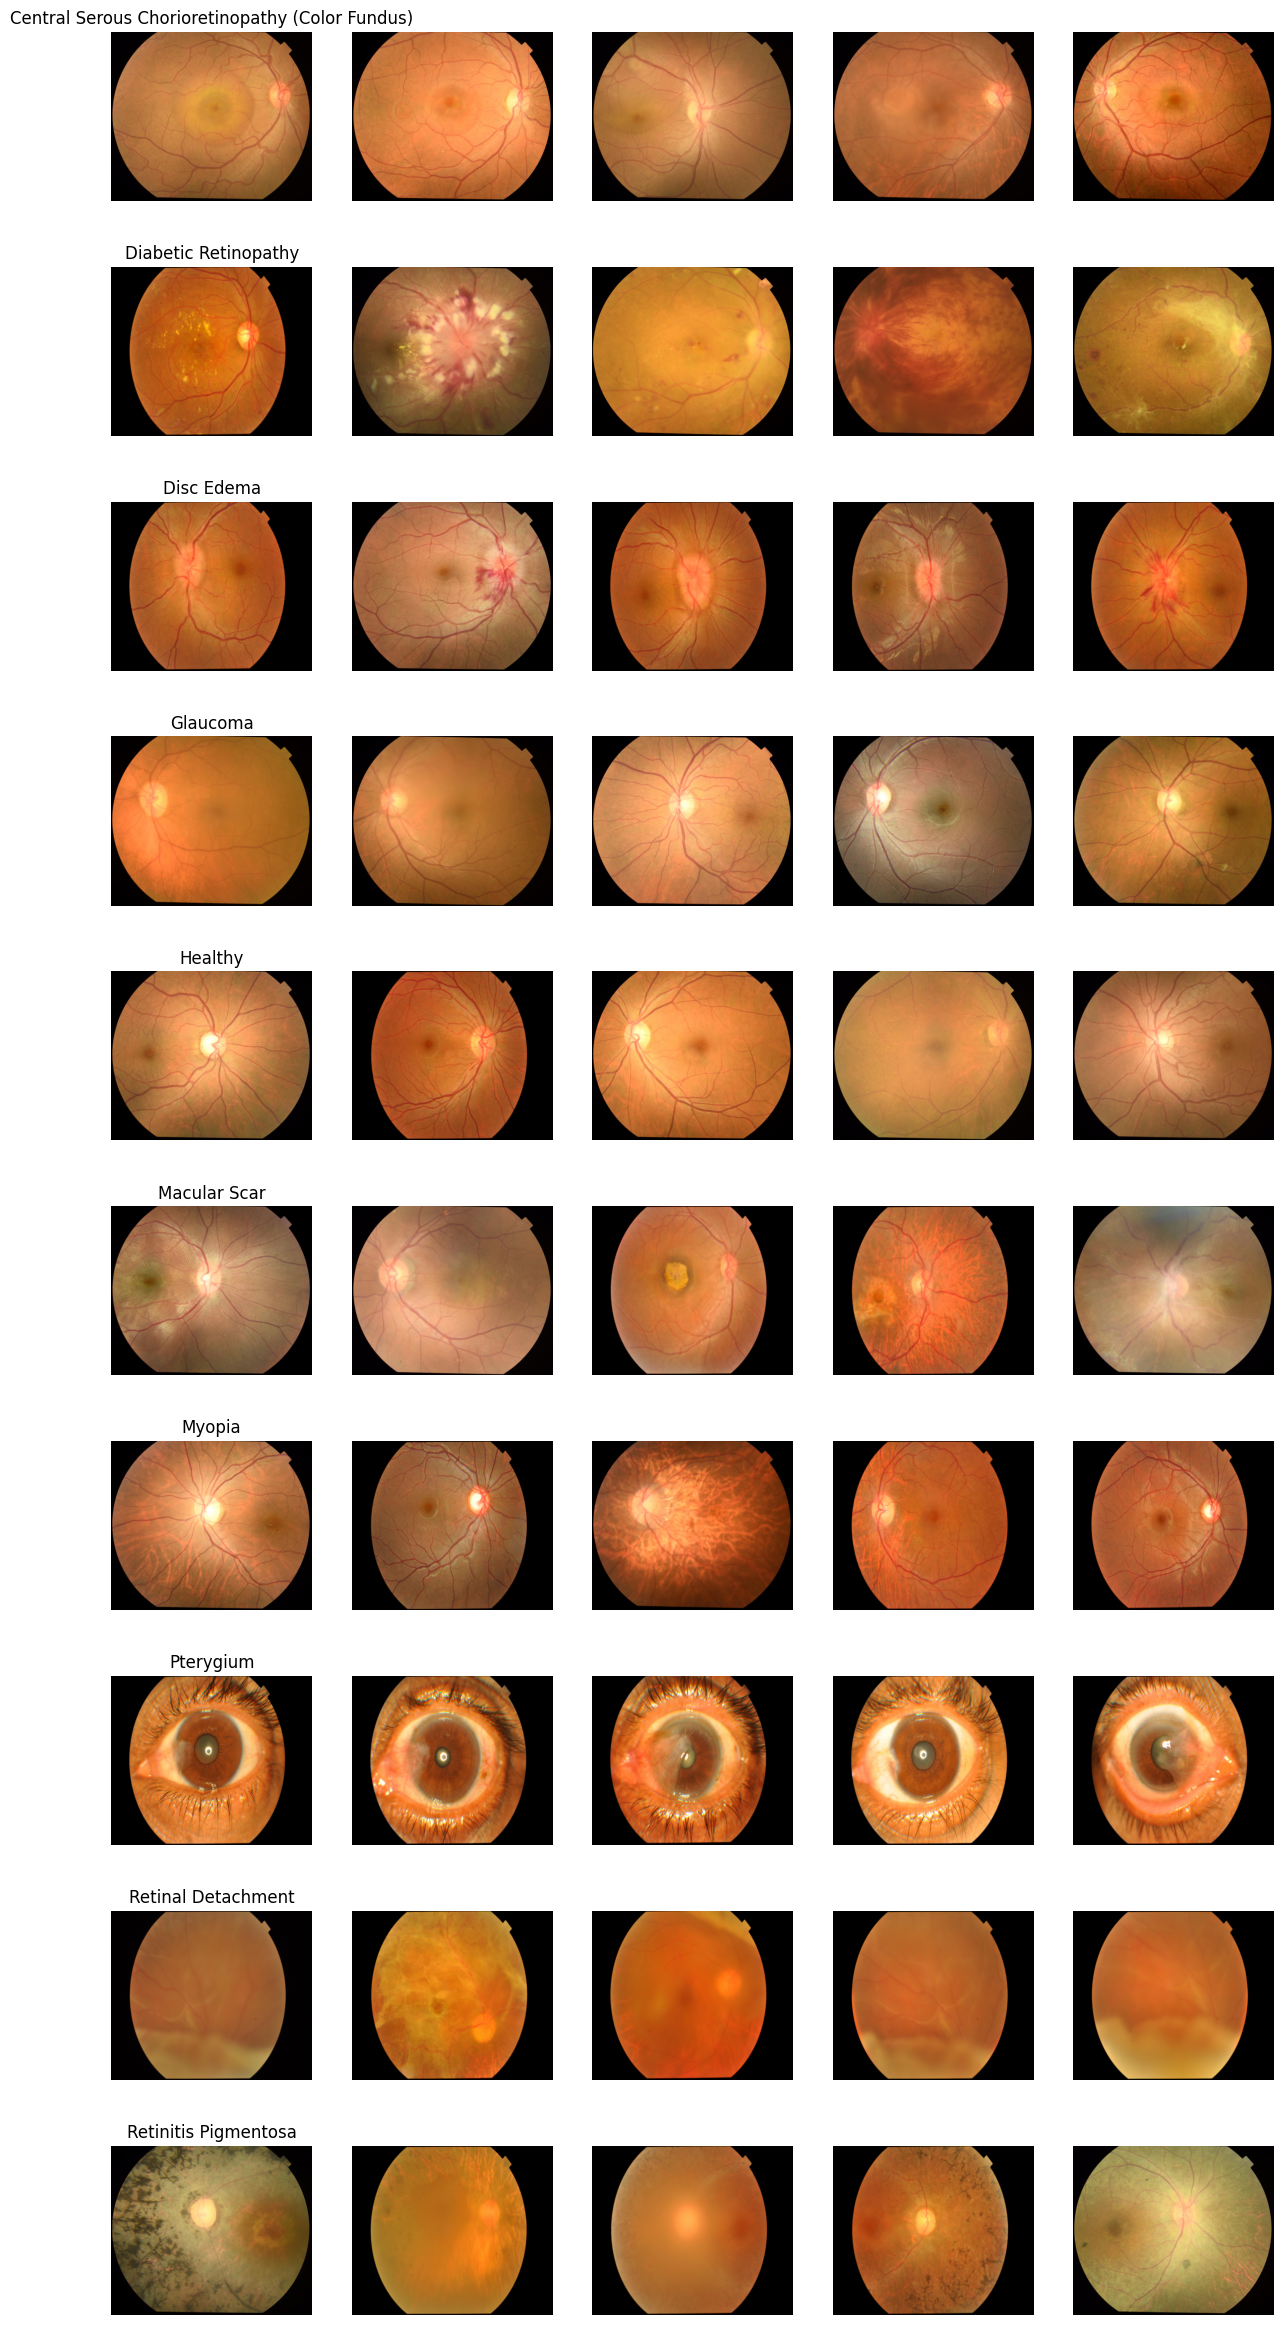

In [4]:
# Some sample images
import random
import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(classes), 5, figsize=(15, len(classes) * 3))
for i, cls in enumerate(classes):
    class_dir = os.path.join(DATA_PATH, cls)
    for j in range(5):
        img_path = os.path.join(class_dir, random.choice(os.listdir(class_dir)))
        img = Image.open(img_path)
        axes[i, j].imshow(img)
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(cls)
plt.show()


In [5]:
class EyeDataset(Dataset):
    def __init__(self, file_paths, labels, transform=None):
        self.file_paths = file_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        img_path = self.file_paths[idx]
        label = self.labels[idx]
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, label


In [6]:
# Transforms
IMG_SIZE = 224
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomResizedCrop(IMG_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])
val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

In [7]:
# Collect file paths and labels
file_paths, labels = [], []
for idx, cls in enumerate(CLASSES):
    cls_path = os.path.join(DATA_PATH, cls)
    for f in os.listdir(cls_path):
        if f.lower().endswith((".png", ".jpg", ".jpeg")):
            file_paths.append(os.path.join(cls_path, f))
            labels.append(idx)

file_paths = np.array(file_paths)
labels = np.array(labels)

# Train/Val/Test split
X_train, X_temp, y_train, y_temp = train_test_split(file_paths, labels, test_size=0.3, stratify=labels, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=SEED)

print(f"Train_size: {len(X_train)}\nVal_size: {len(X_val)}\nTest_size: {len(X_test)}")

train_dataset = EyeDataset(X_train, y_train, transform=train_transform)
val_dataset = EyeDataset(X_val, y_val, transform=val_transform)
test_dataset = EyeDataset(X_test, y_test, transform=val_transform)

BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)


Train_size: 3734
Val_size: 800
Test_size: 801


In [ ]:
# Load Vision Transformer model from timm and remove classifier head. Supported models: convit_small, mobilevit_s, efficientvit_b0
def get_vit_backbone(model_name):
    model = timm.create_model(model_name, pretrained=True)
 
    # Remove classifier head
    if hasattr(model, 'head'):
        model.head = nn.Identity()
    elif hasattr(model, 'classifier'):
        model.classifier = nn.Identity()
    elif hasattr(model, 'fc'):
        model.fc = nn.Identity()
    else:
        raise ValueError(f"Unable to remove classifier for {model_name}")

    model.eval()
    model.to(DEVICE)
    return model

def extract_features(model, dataloader, output_dim=2048):
    """Extract flattened embeddings from the Vision Transformer with optional dimensionality reduction."""
    model.eval()
    features, labels_list = [], []
    with torch.no_grad():
        for imgs, lbls in tqdm(dataloader, desc="Extracting Features"):
            imgs = imgs.to(DEVICE)
            feats = model(imgs)
            
            # Flatten if needed
            if len(feats.shape) > 2:
                feats = torch.flatten(feats, 1)
            
            # Reduce feature size with AdaptiveAvgPool1d
            if feats.shape[1] > output_dim:
                feats = nn.AdaptiveAvgPool1d(output_dim)(feats.unsqueeze(0)).squeeze(0)
            
            features.append(feats.cpu().numpy())
            labels_list.append(lbls.numpy())

    return np.vstack(features), np.concatenate(labels_list)


In [ ]:
# Backbone–Symbolic comparison (auto-selection with tuning + full metrics)

from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, log_loss
)
from scipy.stats import randint, uniform
import numpy as np
import pandas as pd

symbolic_models = {
    
    "RandomForest": (
        RandomForestClassifier(random_state=SEED),
        {
            "n_estimators": randint(50, 100),
            "max_depth": randint(5, 50),
            "min_samples_split": randint(2, 20),
            "min_samples_leaf": randint(1, 10),
            "max_features": ["sqrt", "log2", None],
            "bootstrap": [True, False]
        }
    ),
    "XGBoost": (
        xgb.XGBClassifier(use_label_encoder=False, eval_metric="mlogloss", random_state=SEED),
        {
            "n_estimators": randint(50, 100),
            "max_depth": randint(3, 15),
            "learning_rate": uniform(0.01, 0.3),
            "subsample": uniform(0.5, 0.5),
            "colsample_bytree": uniform(0.5, 0.5),
            "gamma": uniform(0, 5),
            "reg_alpha": uniform(0, 1),
            "reg_lambda": uniform(0, 1)
        }
    ),
    
    "LightGBM": (
        lgb.LGBMClassifier(verbose=-1, random_state=SEED),
        {
            "n_estimators": randint(50, 100),
            "max_depth": randint(3, 15),
            "learning_rate": uniform(0.01, 0.3),
            "subsample": uniform(0.5, 0.5),
            "colsample_bytree": uniform(0.5, 0.5),
            "gamma": uniform(0, 5),
            "reg_alpha": uniform(0, 1),
            "reg_lambda": uniform(0, 1)
        }
    ),
    "CatBoost": (
        cb.CatBoostClassifier(verbose=0,random_state=SEED),
        {
            "iterations": randint(50, 100),
            "depth": randint(3, 12),
            "learning_rate": uniform(0.01, 0.3),
            "l2_leaf_reg": uniform(1, 10),
            "border_count": randint(32, 255),
            "random_strength": uniform(0, 10)
        }
    ),
    "AdaBoost": (
        AdaBoostClassifier(random_state=SEED),
        {
           "n_estimators": randint(50, 100),
            "learning_rate": uniform(0.01, 1.0),
            "algorithm": ["SAMME", "SAMME.R"]
        }
    ),
    "GradientBoosting": (
        GradientBoostingClassifier(random_state=SEED),
        {
             "n_estimators": randint(50, 100),
            "learning_rate": uniform(0.01, 0.3),
            "max_depth": randint(3, 15),
            "min_samples_split": randint(2, 20),
            "min_samples_leaf": randint(1, 10),
            "subsample": uniform(0.5, 1.0),
            "max_features": ["sqrt", "log2", None]
        }
    )
}

backbones = ["efficientvit_b0", "mobilevit_s", "convit_small"]
results_summary = []

for backbone_name in backbones:
    print(f"\nTesting Backbone: {backbone_name}")
    
    model = get_vit_backbone(backbone_name)
    X_train_feat, y_train_feat = extract_features(model, train_loader)
    X_val_feat, y_val_feat     = extract_features(model, val_loader)
    
    for sym_name, (sym_model, param_dist) in symbolic_models.items():
        print(f"\nTuning {sym_name} for {backbone_name}...")
        search = RandomizedSearchCV(
            sym_model,
            param_distributions=param_dist,
            n_iter=10,
            scoring="accuracy",
            cv=3,
            verbose=1,
            random_state=SEED,
            n_jobs=1
        )
        search.fit(X_train_feat, y_train_feat)
        
        best_params = search.best_params_
        tuned_model = search.best_estimator_
        
        # Evaluate on train/val
        val_preds = tuned_model.predict(X_val_feat)
        val_probs = tuned_model.predict_proba(X_val_feat)
        train_preds = tuned_model.predict(X_train_feat)
        train_probs = tuned_model.predict_proba(X_train_feat)
        
        train_acc = accuracy_score(y_train_feat, train_preds)
        val_acc = accuracy_score(y_val_feat, val_preds)
        train_loss = log_loss(y_train_feat, train_probs)
        val_loss = log_loss(y_val_feat, val_probs)

        # Evaluation metrics 
        overall_acc = accuracy_score(y_val_feat, val_preds)
        precision = precision_score(y_val_feat, val_preds, average="weighted", zero_division=0)
        recall = recall_score(y_val_feat, val_preds, average="weighted", zero_division=0)
        f1 = f1_score(y_val_feat, val_preds, average="weighted", zero_division=0)
        class_report = classification_report(y_val_feat, val_preds, zero_division=0)
        conf_matrix = confusion_matrix(y_val_feat, val_preds)

        print(f"\n{backbone_name} + {sym_name}")
        print(f"Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")
        print(f"Accuracy: {overall_acc:.4f} | Precision: {precision:.4f} | Recall: {recall:.4f} | F1-score: {f1:.4f}")
        print(f"Best Params: {best_params}")
        print("Classification Report:\n", class_report)
        print("Confusion Matrix:\n", conf_matrix)

        # Store everything
        results_summary.append({
            "backbone": backbone_name,
            "symbolic_model": sym_name,
            "train_acc": train_acc,
            "val_acc": val_acc,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "overall_acc": overall_acc,
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "conf_matrix": conf_matrix,
            "class_report": class_report,
            "best_params": best_params,
            "model": tuned_model,
            "backbone_model": model
        })

    # After finishing all symbolic models for this backbone
    print(f"\nCompleted backbone {backbone_name} summary:")
    for r in [res for res in results_summary if res["backbone"] == backbone_name]:
        print(f"{r['symbolic_model']:<15} | Train Acc : {r['train_acc']:.4f} | "
              f"Train Loss : {r['train_loss']:.4f} | Val Acc: {r['val_acc']:.4f} | "
              f"Val Loss: {r['val_loss']:.4f} | Accuracy : {r['overall_acc']:.4f}| "
              f"Precision : {r['precision']:.4f} | Recall : {r['recall']:.4f} | F1: {r['f1']:.4f}") 

# Select the best combination

best_combo = max(results_summary, key=lambda x: (x["val_acc"], -x["val_loss"]))

print(f"\nBest Backbone–Symbolic Pair:")
print(f"Backbone: {best_combo['backbone']}")
print(f"Symbolic Model: {best_combo['symbolic_model']}")
print(f"Training Accuracy: {best_combo['train_acc']:.4f}, Training Loss: {best_combo['train_loss']:.4f}")
print(f"Validation Accuracy: {best_combo['val_acc']:.4f}, Validation Loss: {best_combo['val_loss']:.4f}")
print(f"Best Params: {best_combo['best_params']}")
print(f"Overall Accuracy: {best_combo['overall_acc']:.4f}")
print(f"Precision: {best_combo['precision']:.4f}, Recall: {best_combo['recall']:.4f}, F1: {best_combo['f1']:.4f}")
print("Classification Report:\n", best_combo["class_report"])
print("Confusion Matrix:\n", best_combo["conf_matrix"])

# Save the features for further hybrid integration
X_train_feat, y_train_feat = extract_features(best_combo["backbone_model"], train_loader)
X_val_feat, y_val_feat     = extract_features(best_combo["backbone_model"], val_loader)





Testing Backbone: efficientvit_b0


Extracting Features: 100%|██████████| 25/25 [00:19<00:00,  1.30it/s]



Tuning RandomForest for efficientvit_b0...
Fitting 3 folds for each of 10 candidates, totalling 30 fits

efficientvit_b0 + RandomForest
Train Acc: 0.8891 | Val Acc: 0.5663 | Train Loss: 0.7142 | Val Loss: 1.2765
Accuracy: 0.5663 | Precision: 0.4999 | Recall: 0.5663 | F1-score: 0.4929
Best Params: {'bootstrap': True, 'max_depth': 15, 'max_features': None, 'min_samples_leaf': 8, 'min_samples_split': 5, 'n_estimators': 89}
Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00        15
           1       0.67      0.91      0.77       226
           2       0.00      0.00      0.00        19
           3       0.45      0.85      0.59       202
           4       0.65      0.39      0.48       153
           5       0.00      0.00      0.00        67
           6       0.78      0.24      0.37        75
           7       0.00      0.00      0.00         3
           8       0.00      0.00      0.00        19
          

Extracting Features: 100%|██████████| 25/25 [00:17<00:00,  1.46it/s]



Tuning RandomForest for mobilevit_s...
Fitting 3 folds for each of 10 candidates, totalling 30 fits

mobilevit_s + RandomForest
Train Acc: 0.8728 | Val Acc: 0.4138 | Train Loss: 0.7785 | Val Loss: 1.5990
Accuracy: 0.4138 | Precision: 0.3540 | Recall: 0.4138 | F1-score: 0.3495
Best Params: {'bootstrap': False, 'max_depth': 26, 'max_features': 'sqrt', 'min_samples_leaf': 9, 'min_samples_split': 18, 'n_estimators': 76}
Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00        15
           1       0.51      0.69      0.59       226
           2       0.00      0.00      0.00        19
           3       0.33      0.65      0.44       202
           4       0.45      0.24      0.31       153
           5       0.00      0.00      0.00        67
           6       0.43      0.08      0.13        75
           7       0.00      0.00      0.00         3
           8       0.00      0.00      0.00        19
           9  

Extracting Features: 100%|██████████| 25/25 [00:24<00:00,  1.04it/s]



Tuning RandomForest for convit_small...
Fitting 3 folds for each of 10 candidates, totalling 30 fits

convit_small + RandomForest
Train Acc: 0.8731 | Val Acc: 0.5800 | Train Loss: 0.7457 | Val Loss: 1.2802
Accuracy: 0.5800 | Precision: 0.5158 | Recall: 0.5800 | F1-score: 0.5189
Best Params: {'bootstrap': True, 'max_depth': 33, 'max_features': None, 'min_samples_leaf': 8, 'min_samples_split': 8, 'n_estimators': 68}
Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00        15
           1       0.74      0.88      0.80       226
           2       0.00      0.00      0.00        19
           3       0.46      0.85      0.60       202
           4       0.57      0.43      0.49       153
           5       0.00      0.00      0.00        67
           6       0.60      0.36      0.45        75
           7       0.00      0.00      0.00         3
           8       1.00      0.11      0.19        19
           9    

Extracting Features: 100%|██████████| 25/25 [00:24<00:00,  1.02it/s]


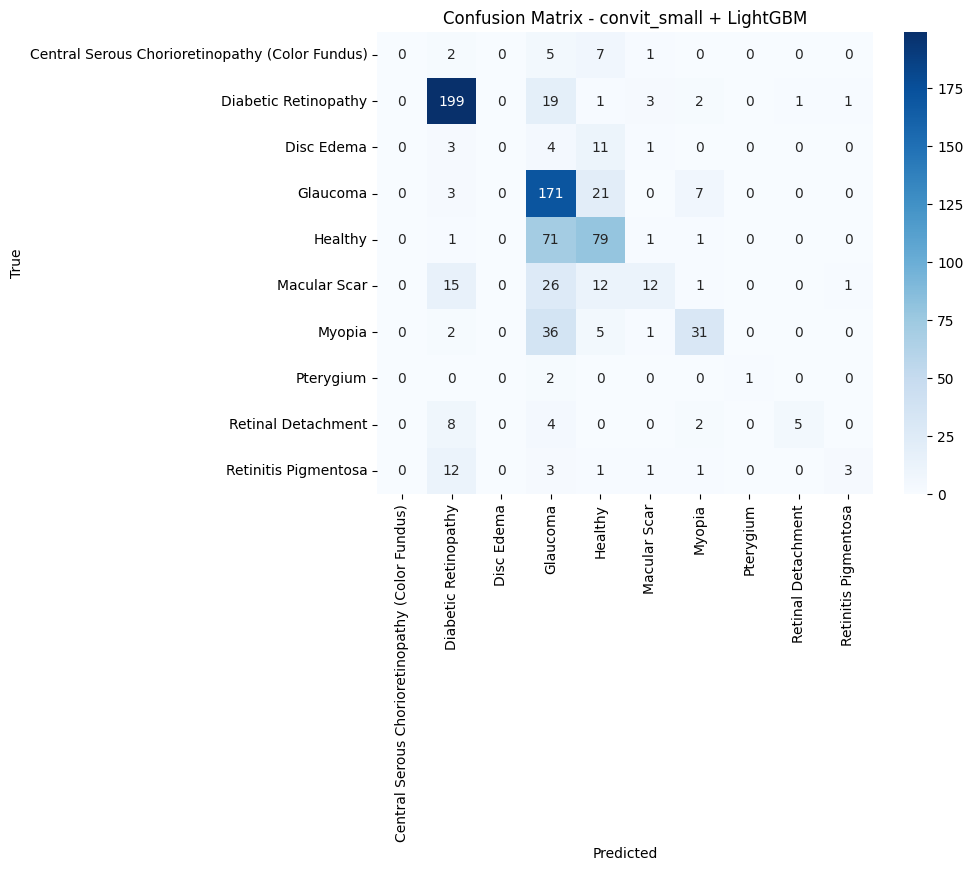

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

# Extract the confusion matrix and class labels
best_conf_matrix = best_combo["conf_matrix"]
class_labels = CLASSES 

plt.figure(figsize=(8, 6))
sns.heatmap(best_conf_matrix,annot=True,fmt="d",cmap="Blues",xticklabels=class_labels,yticklabels=class_labels)
plt.title(f"Confusion Matrix - {best_combo['backbone']} + {best_combo['symbolic_model']}")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()



Visualizing Best Combination: convit_small + LightGBM


Extracting Features: 100%|██████████| 25/25 [00:25<00:00,  1.02s/it]


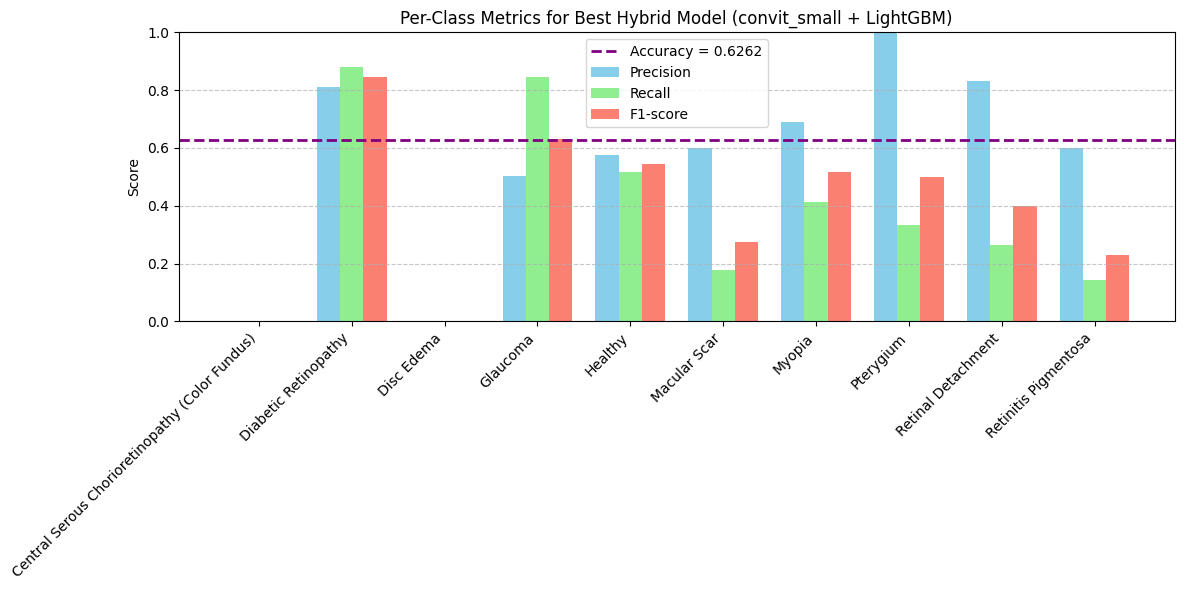

In [11]:
#Visualization of Best Backbone–Symbolic Hybrid 

from sklearn.metrics import precision_recall_fscore_support, accuracy_score
import numpy as np
import matplotlib.pyplot as plt

# Extract validation features & predictions for the best model
best_model = best_combo["model"]
backbone_model = best_combo["backbone_model"]

print(f"\nVisualizing Best Combination: {best_combo['backbone']} + {best_combo['symbolic_model']}")

# Get validation features and true labels
X_val_feat, y_val_feat = extract_features(backbone_model, val_loader)
y_pred = best_model.predict(X_val_feat)
y_true = y_val_feat

# Compute metrics per class
precision, recall, f1, _ = precision_recall_fscore_support(
    y_true, y_pred, labels=range(len(CLASSES))
)
accuracy = accuracy_score(y_true, y_pred)

# Create bar chart
x = np.arange(len(CLASSES))
width = 0.25

plt.figure(figsize=(12, 6))
plt.bar(x - width, precision, width=width, label='Precision', color='skyblue')
plt.bar(x, recall, width=width, label='Recall', color='lightgreen')
plt.bar(x + width, f1, width=width, label='F1-score', color='salmon')

# Plot overall accuracy as a dashed line
plt.axhline(y=accuracy, color='purple', linestyle='--', linewidth=2,
            label=f'Accuracy = {accuracy:.4f}')

# Label formatting
plt.xticks(x, CLASSES, rotation=45, ha='right')
plt.ylim(0, 1.0)
plt.ylabel('Score')
plt.title(f"Per-Class Metrics for Best Hybrid Model ({best_combo['backbone']} + {best_combo['symbolic_model']})")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


Class label mapping:
Label 0 -> Central Serous Chorioretinopathy (Color Fundus)
Label 1 -> Diabetic Retinopathy
Label 2 -> Disc Edema
Label 3 -> Glaucoma
Label 4 -> Healthy
Label 5 -> Macular Scar
Label 6 -> Myopia
Label 7 -> Pterygium
Label 8 -> Retinal Detachment
Label 9 -> Retinitis Pigmentosa

Extracting features for t-SNE: efficientvit_b0


Extracting Features: 100%|██████████| 117/117 [01:51<00:00,  1.05it/s]


Plotting t-SNE for efficientvit_b0 features...



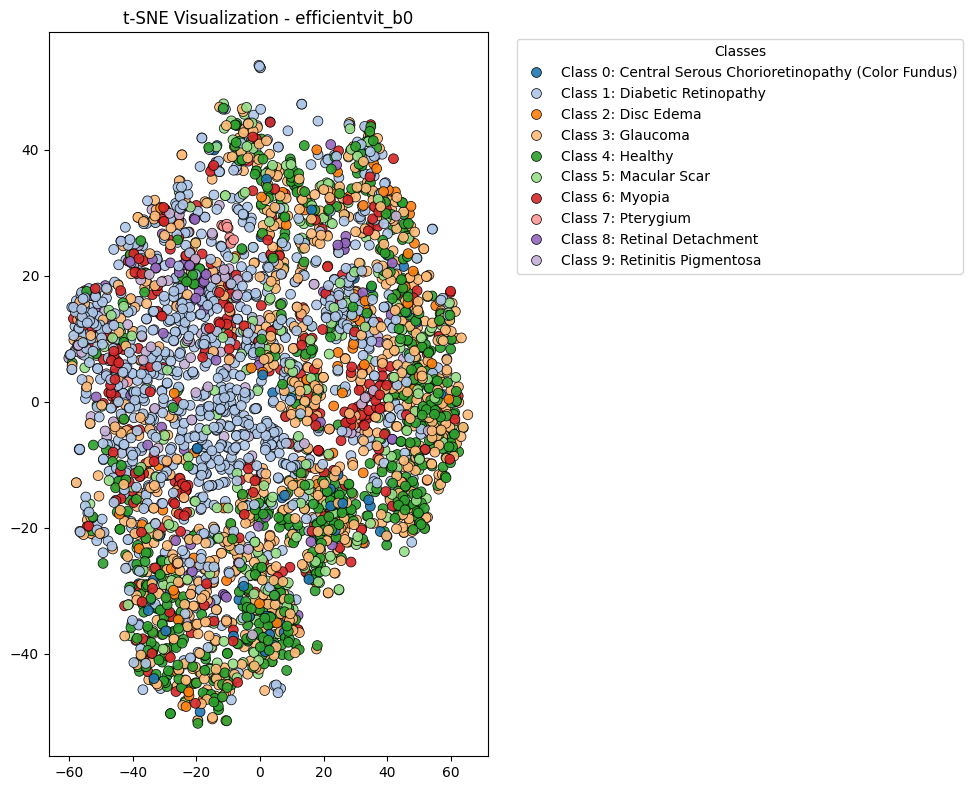


Extracting features for t-SNE: mobilevit_s


Extracting Features: 100%|██████████| 117/117 [01:59<00:00,  1.02s/it]


Plotting t-SNE for mobilevit_s features...



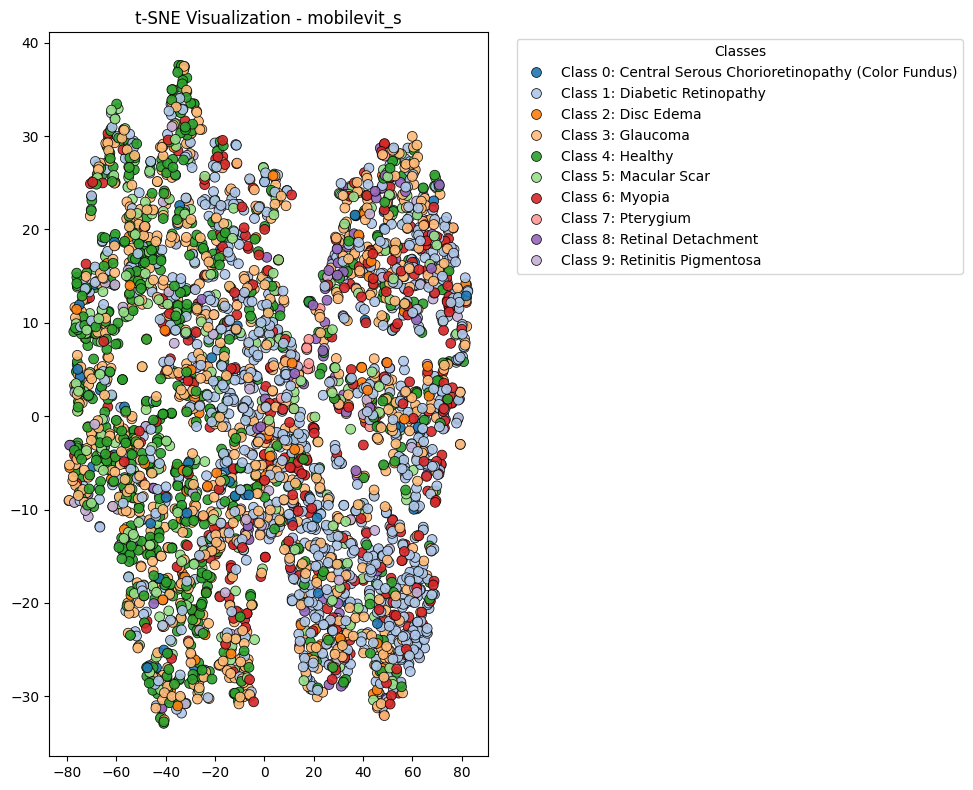


Extracting features for t-SNE: convit_small


Extracting Features: 100%|██████████| 117/117 [01:59<00:00,  1.02s/it]


Plotting t-SNE for convit_small features...



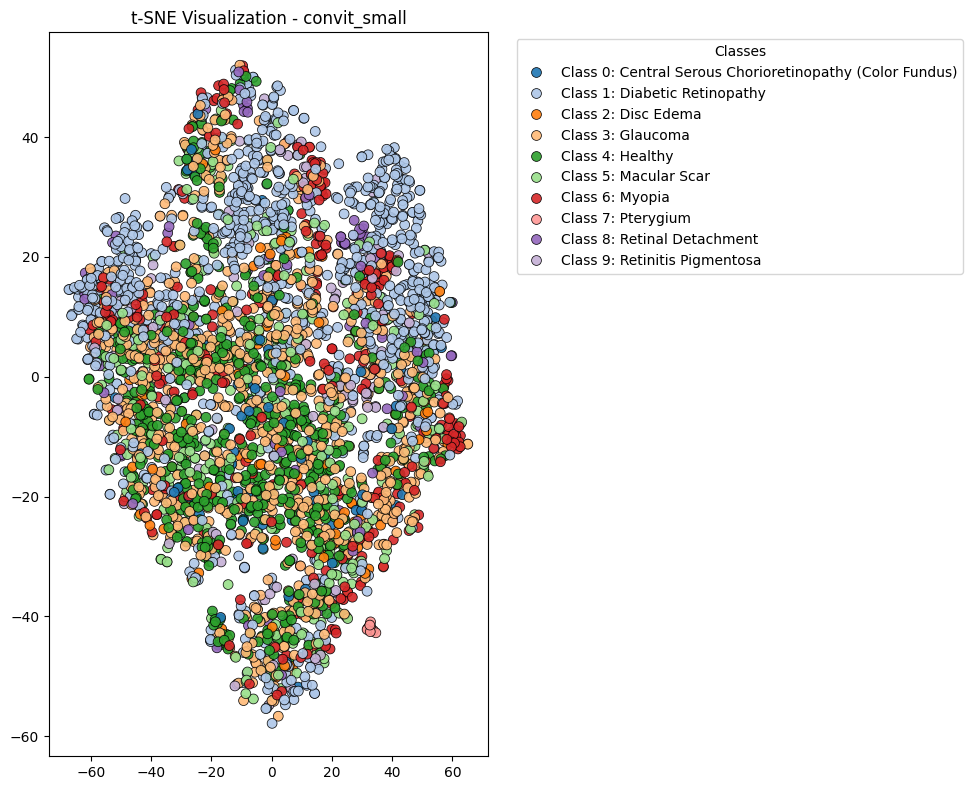

In [13]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns

def plot_tsne(features, labels, title):
    
    #Perform t-SNE on features and plot with color-coded labels.
    
    tsne = TSNE(n_components=2, random_state=SEED)
    feat_2d = tsne.fit_transform(features)
    print()
    plt.figure(figsize=(10, 8))
    palette = sns.color_palette("tab20", len(np.unique(labels)))
    scatter = sns.scatterplot(x=feat_2d[:, 0], y=feat_2d[:, 1], hue=labels, legend="full", palette=palette, s=50, edgecolor = 'k', alpha = 0.9)
    plt.title(title)
    handles, _ = scatter.get_legend_handles_labels()
    new_labels = [f"Class {i}: {CLASSES[i]}" for i in np.unique(labels)]
    plt.legend(
        handles=handles,
        labels=new_labels,
        title="Classes",
        bbox_to_anchor=(1.05, 1),
        loc='upper left'
    )
    plt.tight_layout()
    plt.show()

# Print class label mapping
print("Class label mapping:")
for idx, cls_name in enumerate(CLASSES):
    print(f"Label {idx} -> {cls_name}")
    
# Run t-SNE for each backbone
for backbone_name in backbones:
    print(f"\nExtracting features for t-SNE: {backbone_name}")
    backbone_model = get_vit_backbone(backbone_name)
    
    X_train_feat, y_train_feat = extract_features(backbone_model, train_loader)
    
    print(f"Plotting t-SNE for {backbone_name} features...")
    plot_tsne(X_train_feat, y_train_feat, title=f"t-SNE Visualization - {backbone_name}")
